# 04 Yearly results

For each calendar year: the mean pairwise correlation of daily returns, a 95% bootstrap confidence interval (200 resamples of days), and the share of variance explained by the first principal component (PC1). `src/results.py` does the work and writes `figures/yearly_results.csv`.

2019 to 2021 come from yfinance, which fills the gap in the Polygon data (see the data section of `docs/analysis.md`). `full_year_members` counts stocks that were in the index for the whole year, and `members_excluded` counts how many of those are missing from the calculation, mostly delisted companies that no source serves.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import src.results as results

In [2]:
yearly = results.main()

      n_days  coverage  n_tickers  full_year_members  members_excluded  mean_corr  ci_low  ci_high  pc1_share
year                                                                                                         
2004     100      0.38        387                440                53      0.232   0.167    0.304      0.256
2005      98      0.38        391                443                52      0.198   0.156    0.245      0.225
2006     113      0.43        380                425                45      0.220   0.160    0.278      0.253
2007     130      0.50        371                413                42      0.348   0.286    0.403      0.369
2008     125      0.48        379                413                35      0.448   0.363    0.542      0.462
2009     111      0.43        390                417                30      0.411   0.357    0.471      0.440
2010      99      0.38        401                435                34      0.461   0.381    0.537      0.483
2011     1

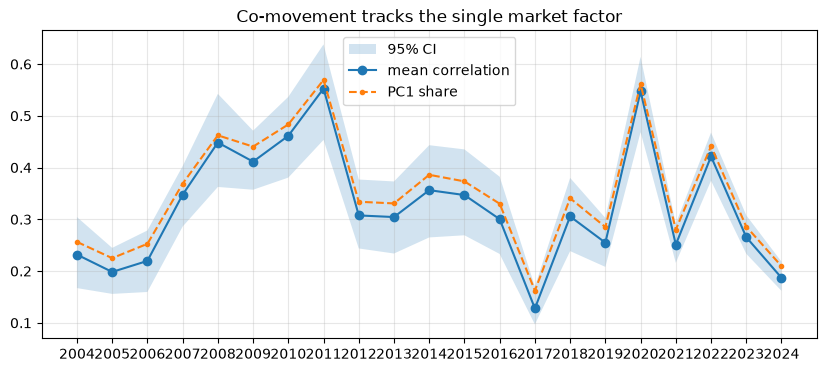

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(yearly.index, yearly.ci_low, yearly.ci_high, alpha=0.2, label="95% CI")
ax.plot(yearly.mean_corr, marker="o", label="mean correlation")
ax.plot(yearly.pc1_share, ls="--", marker=".", label="PC1 share")
ax.set_xticks(yearly.index)
ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Co-movement tracks the single market factor")
plt.show()

PC1's share tracks mean correlation to within 0.035 every year, so the series measures how strong the single market factor is. The two highest years are 2011 at 0.553 and 2020 at 0.547, with overlapping confidence intervals, followed by 2010 and 2008. The low point is 0.13 in 2017. Notebook 05 asks how much of this movement is volatility.